In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Adım 1: Veri Seti Oluşturma ---
data = {
    'Kargo_Agirlik_Kg': [0.5, 1.2, 3.0, 5.0, 0.8, 2.5, 4.0, 10.0, 1.5, 6.0],
    'Mesafe_Km': [5, 12, 25, 40, 8, 18, 30, 85, 10, 50],
    'Trafik_Yogunluk_Puani': [2, 4, 3, 5, 1, 4, 5, 3, 2, 4],
    'Teslimat_Suresi_Dk': [15, 30, 55, 80, 20, 45, 70, 140, 25, 95] # Hedef (y)
}
df = pd.DataFrame(data)

In [2]:
df

,Kargo_Agirlik_Kg,Mesafe_Km,Trafik_Yogunluk_Puani,Teslimat_Suresi_Dk
0,0.5,5,2,15
1,1.2,12,4,30
2,3.0,25,3,55
3,5.0,40,5,80
4,0.8,8,1,20
5,2.5,18,4,45
6,4.0,30,5,70
7,10.0,85,3,140
8,1.5,10,2,25
9,6.0,50,4,95


In [3]:
# x ve y ayrımlarını yapacagız
X = df.drop("Teslimat_Suresi_Dk",axis=1)
y=df["Teslimat_Suresi_Dk"]

In [4]:
from sklearn.model_selection import train_test_split

In [6]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [7]:
from sklearn.preprocessing import StandardScaler

In [8]:
scaler = StandardScaler()

In [9]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
from sklearn.linear_model import LinearRegression

In [11]:
regression = LinearRegression()

In [13]:
regression.fit(X_train_scaled,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [14]:
y_pred = regression.predict(X_test_scaled)

In [15]:
print(f"[KOLAY - LOJİSTİK] Sonuçlar:")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.2f}")

[KOLAY - LOJİSTİK] Sonuçlar:
MAE: 3.39
RMSE: 3.40
R2 Score: -0.85


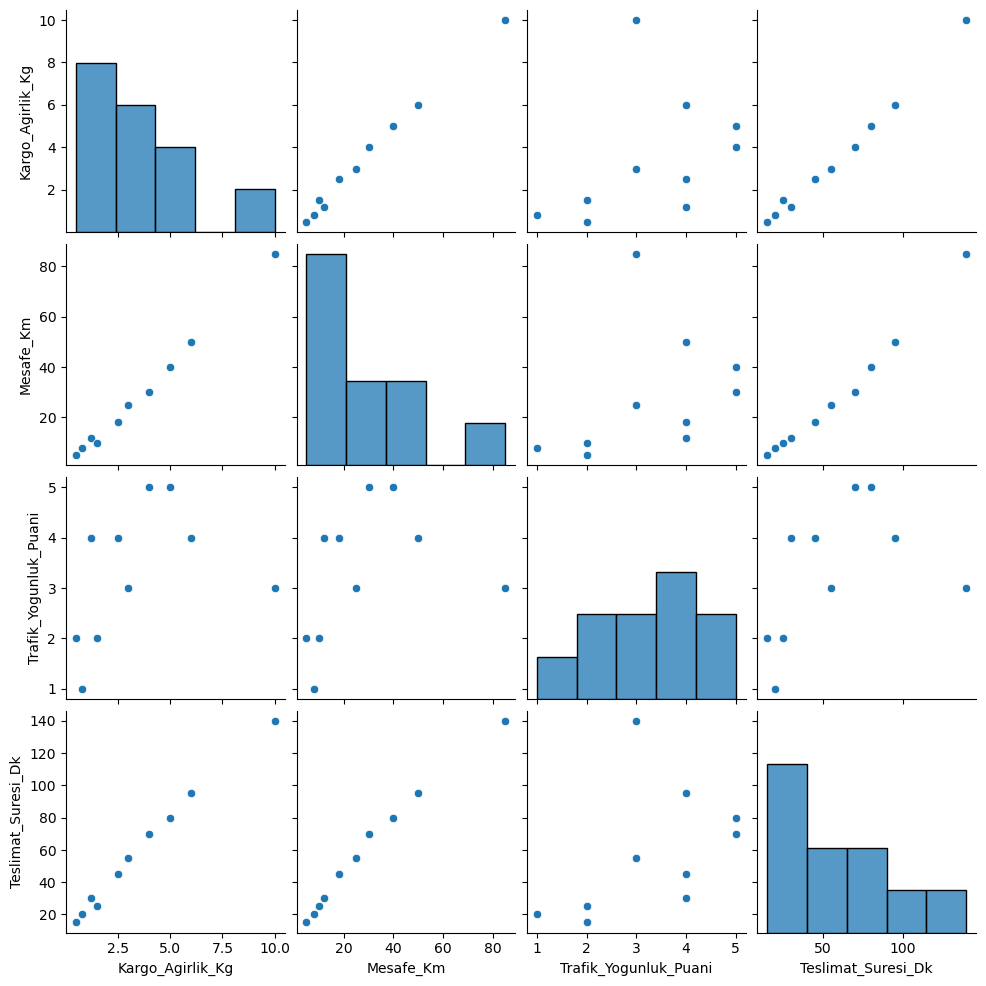

In [16]:
sns.pairplot(df)

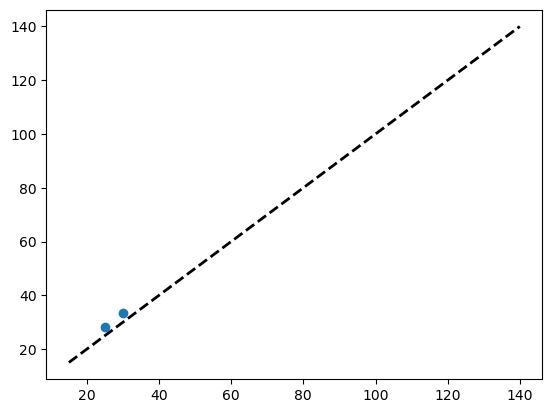

In [18]:
plt.scatter(y_test,y_pred)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2) # İdeal 45 derece çizgisi
plt.show()

In [19]:
residuals = y_test - y_pred


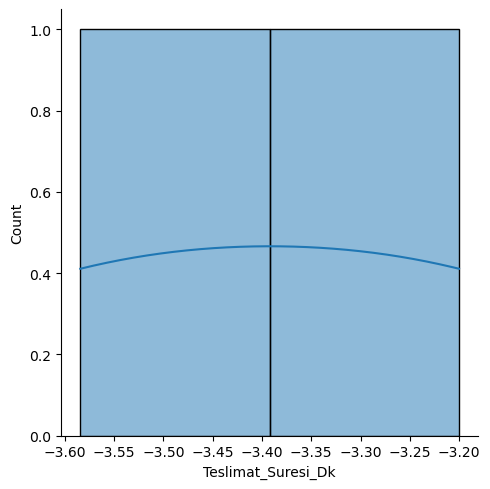

In [21]:
sns.displot(residuals,kde="kde")
plt.show()